1) polyfit  -> slope: 2.3996300006192108e-05 intercept: 5.741754332811532
2) linregress -> slope: 2.3996300006192135e-05 intercept: 5.741754332811531
   r: 0.72 p-value: 3.426555544263645e-07
3) OLS -> params: [5.74175433e+00 2.39963000e-05] R2: 0.519
4) sklearn -> R2: 0.519
   GDP 30000 par predicted satisfaction: 6.461643332997294


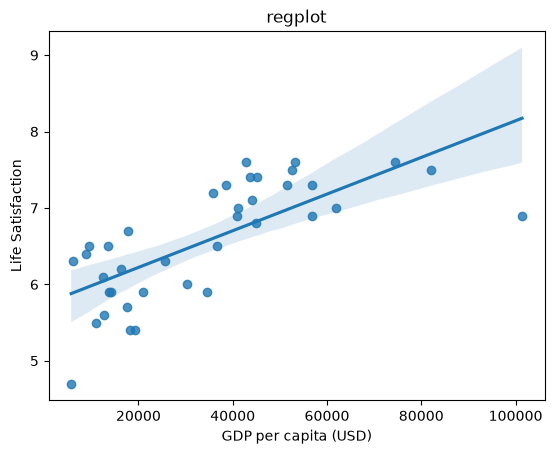

      Hours  Passed
0  7.739560       1
1  4.388784       1
2  8.585979       1
3  6.973680       1
4  0.941773       0
Passed
1    104
0     96
Name: count, dtype: int64
Coef: 1.2971848548186917 Intercept: -6.014367101533722
3 ghante -> class: 0, probability [Fail, Pass]: [0.893 0.107]
8 ghante -> class: 1, probability [Fail, Pass]: [0.013 0.987]
Accuracy: 0.9
Confusion Matrix:
 [[18  3]
 [ 1 18]]
              precision    recall  f1-score   support

           0       0.95      0.86      0.90        21
           1       0.86      0.95      0.90        19

    accuracy                           0.90        40
   macro avg       0.90      0.90      0.90        40
weighted avg       0.90      0.90      0.90        40



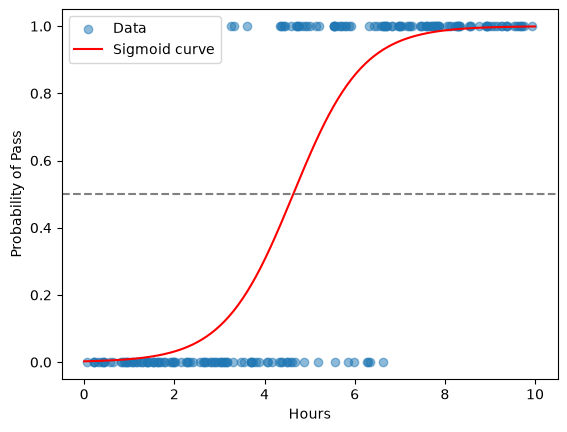

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ============================================
# PART 1: Article ke 5 modules (GDP vs Life Satisfaction)
# ============================================
x = np.array([56755.72, 44178.05, 40991.81, 8814.00, 43585.51, 13574.17, 6175.88, 17829.70, 53254.86, 17522.23, 42784.70, 36638.18, 41086.73, 18167.77, 12706.89, 52564.43, 61995.42, 35776.80, 30230.23, 34524.47, 13774.61, 14258.23, 101376.50, 9616.65, 45175.23, 38615.99, 74355.52, 12578.50, 19242.37, 16310.99, 20881.77, 5734.63, 25732.02, 51545.48, 82081.60, 11006.25, 44974.83, 56839.38])
y = np.array([7.3,7.1,6.9,6.4,7.4,6.5,6.3,6.7,7.6,5.7,7.6,6.5,7.0,5.4,5.6,7.5,7.0,7.2,6.0,5.9,5.9,5.9,6.9,6.5,7.4,7.3,7.6,6.1,5.4,6.2,5.9,4.7,6.3,7.3,7.5,5.5,6.8,6.9])

# 1) NumPy polyfit
slope, intercept = np.polyfit(x, y, 1)
print("1) polyfit  -> slope:", slope, "intercept:", intercept)

# 2) SciPy linregress
r = stats.linregress(x, y)
print("2) linregress -> slope:", r.slope, "intercept:", r.intercept)
print("   r:", round(r.rvalue, 3), "p-value:", r.pvalue)

# 3) statsmodels OLS (constant khud add karna parta hai)
res = sm.OLS(y, sm.add_constant(x)).fit()
print("3) OLS -> params:", res.params, "R2:", round(res.rsquared, 3))
# print(res.summary())   # poori table dekhne ke liye

# 4) sklearn LinearRegression
lin = LinearRegression().fit(x.reshape(-1, 1), y)
print("4) sklearn -> R2:", round(lin.score(x.reshape(-1, 1), y), 3))
print("   GDP 30000 par predicted satisfaction:", lin.predict([[30000]])[0])

# 5) seaborn regplot (line + 95% confidence area)
plt.figure()
sns.regplot(x=x, y=y, ci=95)
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life Satisfaction")
plt.title("regplot")
plt.show()

# ============================================
# PART 2: LOGISTIC REGRESSION (Hours -> Pass/Fail)
# ============================================
rng = np.random.default_rng(42)
n = 200
hours = rng.uniform(0, 10, n)
prob = 1 / (1 + np.exp(-(1.2 * hours - 6)))   # sigmoid
passed = rng.binomial(1, prob)                # 0 = Fail, 1 = Pass

df = pd.DataFrame({"Hours": hours, "Passed": passed})
print(df.head())
print(df["Passed"].value_counts())

X = df[["Hours"]]
yy = df["Passed"]
X_train, X_test, y_train, y_test = train_test_split(
    X, yy, test_size=0.2, random_state=42
)

clf = LogisticRegression()
clf.fit(X_train, y_train)

print("Coef:", clf.coef_[0][0], "Intercept:", clf.intercept_[0])

# Naye students ka prediction
for h in [3, 8]:
    new = pd.DataFrame({"Hours": [h]})
    print(f"{h} ghante -> class: {clf.predict(new)[0]}, "
          f"probability [Fail, Pass]: {clf.predict_proba(new).round(3)[0]}")

# Evaluation
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Sigmoid curve ka graph
h_line = pd.DataFrame({"Hours": np.linspace(0, 10, 200)})
plt.scatter(df["Hours"], df["Passed"], alpha=0.5, label="Data")
plt.plot(h_line["Hours"], clf.predict_proba(h_line)[:, 1],
         color="red", label="Sigmoid curve")
plt.axhline(0.5, linestyle="--", color="gray")
plt.xlabel("Hours")
plt.ylabel("Probability of Pass")
plt.legend()
plt.show()